# Punto 1: Generación de Texto a Nivel de Carácter con Arquitectura Tipo LLaMA

**Universidad Autónoma de Occidente — Facultad de Ingeniería y Ciencias Básicas**  
**Asignatura:** Inteligencia Artificial Generativa  
**Profesores:** Jesús Alfonso López y José Luis Paniagua  

---

## 1. Marco teórico y justificación de diseño

El notebook base del curso entrena un Transformer decodificador clásico sobre las obras de Shakespeare (`1.115.394` caracteres, `39` caracteres únicos en minúsculas) y alcanza una exactitud de siguiente carácter de `0.567` en prueba. En este primer punto reemplazamos tanto el corpus como el bloque arquitectónico para construir un modelo generativo a nivel de carácter con diseño tipo LLaMA.

### 1.1 Componentes arquitectónicos tipo LLaMA

A diferencia del Transformer original de Vaswani et al. `[Vaswani17]`, que utiliza normalización `LayerNorm` después de cada subcapa (post-norm), codificación posicional absoluta sumada a los embeddings y redes densas con activación ReLU o GELU, la familia LLaMA `[Touvron23]` introduce tres modificaciones estructurales:

1. **Pre-normalización con RMSNorm `[Zhang19]`:** normaliza las activaciones a la entrada de la subcapa de atención y de la subcapa densa usando únicamente la raíz de la media cuadrática, sin restar la media ni aprender sesgo aditivo:
   $$\text{RMSNorm}(x) = \frac{x}{\sqrt{\frac{1}{d}\sum_{i=1}^{d} x_i^2 + \varepsilon}} \odot g$$
   Esto estabiliza los gradientes desde el inicio del entrenamiento y reduce entre un 7% y un 64% el costo computacional de normalización frente a `LayerNorm`.

2. **Codificación posicional rotatoria (RoPE) `[Su21]`:** en lugar de sumar vectores de posición al embedding inicial, RoPE rota cada par de dimensiones de los vectores *query* ($q$) y *key* ($k$) en el plano complejo según un ángulo proporcional a su posición $m$:
   $$f(q, m) = R_{\Theta, m} q, \quad \theta_j = 10000^{-2j/d_{\text{head}}}$$
   Como el producto interno entre dos vectores rotados depende solo de la diferencia de posiciones $(m - n)$, la atención captura distancias relativas de forma natural y extrapola mejor en secuencias largas.

3. **Red feed-forward con compuerta SwiGLU `[Shazeer20]`:** sustituye la capa densa de dos matrices por una compuerta bilineal con activación $\text{SiLU}(z) = z \cdot \sigma(z)$ y tres proyecciones lineales sin sesgo (`bias=False`):
   $$\text{SwiGLU}(x) = \big(\text{SiLU}(x W_{\text{gate}}) \odot (x W_{\text{up}})\big) W_{\text{down}}$$
   Para mantener el mismo presupuesto de parámetros que una FFN tradicional de dimensión $4d$, la dimensión oculta se fija en $\lfloor \frac{8}{3}d \rfloor$.

4. **Modelado profundo a nivel de carácter `[Al-Rfou18]` y escala eficiente `[Bhatti25, Eldan23]`:** trabajar a nivel de carácter elimina por completo el problema de palabras fuera de vocabulario (OOV = 0 en alfabeto visto), a cambio de exigir que las capas de atención compongan morfología y ortografía carácter por carácter. Seleccionamos el corpus **TinyStories** `[Eldan23]` porque concentra narrativas completas con vocabulario cotidiano, permitiendo que modelos compactos converjan dentro del presupuesto de una GPU T4 (Kaggle / Google Colab).

### 1.2 Métricas de evaluación a nivel de carácter

- **Entropía cruzada (`loss`):** pérdida promedio en nats por carácter.
- **Perplejidad (`PPL`):** $\exp(\text{loss})$, mide el factor de ramificación efectivo por carácter.
- **Bits por carácter (`BPC`):** $\text{loss} / \ln(2)$, métrica estándar de compresión que permitirá comparar de forma justa contra el modelo a nivel de palabra en el Punto 2.
- **Exactitud (`accuracy`):** fracción de predicciones donde el carácter más probable coincide con el carácter real siguiente (comparable contra el `0.567` del baseline de Shakespeare).
- **Diversidad y calidad de generación:** `distinct-1`, `distinct-2`, tasa de repetición de trigramas, `BLEU` y `ROUGE-L` sobre continuaciones de prueba a temperaturas $T \in \{0.1, 0.5, 0.8, 1.0\}$.

## 2. Configuración del entorno y reproducibilidad

Fijamos la semilla global (`seed = 42`) en Python, NumPy y PyTorch, y detectamos si estamos ejecutando en una GPU T4 (Kaggle o Colab) o en CPU local.

In [1]:
import contextlib
import glob
import json
import math
import os
import random
import sys
import time
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU local"

print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Dispositivo activo: {DEVICE} ({GPU_NAME})")

Python: 3.13.2
PyTorch: 2.11.0+cpu
Dispositivo activo: cpu (CPU local)


## 3. Carga del corpus TinyStories y comparación con el baseline de Shakespeare

El bloque siguiente localiza `corpus_nuevo.txt` en el directorio de trabajo, en rutas de datasets de Kaggle (`/kaggle/input/...`) o en Google Colab (`/content/...`). Si se ejecuta en una sesión limpia de la nube donde aún no está el archivo, descarga automáticamente la partición de validación de `roneneldan/TinyStories` desde Hugging Face.

Siguiendo el protocolo congelado en `corpus_stats.md`, usamos el **primer millón de caracteres** para entrenamiento (`[:1_000_000]`), los siguientes `60.000` caracteres para validación (`[1_000_000:1_060_000]`) y el resto para prueba, igualando el orden de magnitud del corpus original de Shakespeare (`1.115.394` caracteres).

In [2]:
def ensure_corpus(filename="corpus_nuevo.txt"):
    candidates = [
        filename,
        os.path.join("Proyecto 2", filename),
        os.path.join("/content", filename),
    ] + glob.glob(f"/kaggle/input/**/*{filename}", recursive=True)
    for c in candidates:
        if os.path.exists(c) and os.path.getsize(c) > 100_000:
            return c
    url = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStories-valid.txt"
    print(f"Descargando {filename} desde Hugging Face ({url})...")
    urllib.request.urlretrieve(url, filename)
    return filename

def ensure_shakespeare(filename="shakespeare_baseline.txt"):
    for c in [filename, os.path.join("Proyecto 2", filename)]:
        if os.path.exists(c):
            return c
    url = "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
    urllib.request.urlretrieve(url, filename)
    return filename

corpus_path = ensure_corpus("corpus_nuevo.txt")
shakespeare_path = ensure_shakespeare("shakespeare_baseline.txt")

with open(corpus_path, encoding="utf-8") as f:
    raw_text = f.read()

with open(shakespeare_path, encoding="utf-8") as f:
    shakespeare_text = f.read()

stats_df = pd.DataFrame([
    {
        "Corpus": "Shakespeare (baseline curso)",
        "Archivo": os.path.basename(shakespeare_path),
        "Caracteres totales": f"{len(shakespeare_text):,}",
        "Palabras totales": f"{len(shakespeare_text.split()):,}",
        "Vocab char (lower)": len(set(shakespeare_text.lower())),
        "Vocab word (lower)": f"{len(set(shakespeare_text.lower().split())):,}",
    },
    {
        "Corpus": "TinyStories (corpus nuevo)",
        "Archivo": os.path.basename(corpus_path),
        "Caracteres totales": f"{len(raw_text):,}",
        "Palabras totales": f"{len(raw_text.split()):,}",
        "Vocab char (lower)": len(set(raw_text.lower())),
        "Vocab word (lower)": f"{len(set(raw_text.lower().split())):,}",
    },
])
display(stats_df)
print("\nMuestra del corpus TinyStories (primeros 350 caracteres):")
print(raw_text[:350])

,Corpus,Archivo,Caracteres totales,Palabras totales,Vocab char (lower),Vocab word (lower)
0,Shakespeare (baseline curso),shakespeare_baseline.txt,"1,115,394","202,651",39,"23,641"
1,TinyStories (corpus nuevo),corpus_nuevo.txt,"19,432,979","3,775,640",72,"38,486"



Muestra del corpus TinyStories (primeros 350 caracteres):
 Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."
After playing with the car, Kitty and Spot felt thirsty. They found a small pond with clear water. They drank the water and felt very happy. They played together all day and became best friends.



### 3.1 Partición Train / Val / Test y tokenización a nivel de carácter

Ajustamos los cortes `1.000.000` y `1.060.000` al siguiente espacio en blanco (`_snap_to_space`) para no truncar palabras en la frontera entre entrenamiento y validación, manteniendo exactamente los mismos límites de texto que reutilizaremos en el Punto 2 (nivel de palabra).

In [3]:
def _snap_to_space(text, idx):
    idx = max(0, min(idx, len(text)))
    while idx < len(text) and not text[idx].isspace():
        idx += 1
    return idx

def make_splits(text, train_chars=1_000_000, val_chars=60_000):
    tr_end = _snap_to_space(text, train_chars)
    va_end = _snap_to_space(text, tr_end + val_chars)
    return text[:tr_end], text[tr_end:va_end], text[va_end:]

class CharTok:
    """Tokenizador a nivel de carácter con índice 0 reservado para <UNK>."""
    name = "char"

    def __init__(self, text, lower=True):
        self.lower = lower
        text = text.lower() if lower else text
        self.chars = sorted(set(text))
        self.itos = ["<UNK>"] + self.chars
        self.stoi = {c: i for i, c in enumerate(self.itos)}
        self.unk_id = 0

    def encode(self, s):
        if self.lower:
            s = s.lower()
        return [self.stoi.get(c, self.unk_id) for c in s]

    def decode(self, ids):
        return "".join(self.itos[i] for i in ids if i != self.unk_id)

    def oov_rate(self, text):
        if self.lower:
            text = text.lower()
        return sum(c not in self.stoi for c in text) / max(1, len(text))

    def to_dict(self):
        return {"type": "char", "itos": list(self.itos), "lower": self.lower, "unk_id": self.unk_id}

    @classmethod
    def from_dict(cls, d):
        obj = cls.__new__(cls)
        obj.lower = d.get("lower", True)
        obj.itos = list(d["itos"])
        obj.stoi = {c: i for i, c in enumerate(obj.itos)}
        obj.unk_id = d.get("unk_id", 0)
        obj.chars = obj.itos[1:]
        return obj

    def __len__(self):
        return len(self.itos)

train_text, val_text, test_text = make_splits(raw_text, train_chars=1_000_000, val_chars=60_000)
char_tok = CharTok(train_text)

char_counts = Counter(train_text.lower())
top20_chars = [(repr(c), cnt, round(100 * cnt / len(train_text), 2)) for c, cnt in char_counts.most_common(20)]

print(f"Split train: {len(train_text):,} chars | val: {len(val_text):,} chars | test: {len(test_text):,} chars")
print(f"Vocabulario CharTok (en train): {len(char_tok)} símbolos (incluye <UNK>)")
print(f"Tasa OOV en validación: {char_tok.oov_rate(val_text):.6f}")
print("Caracteres del vocabulario:", "".join(c for c in char_tok.chars if c not in "\n\r\t"))
display(pd.DataFrame(top20_chars, columns=["Carácter", "Frecuencia en Train", "% del Corpus"]).head(10))

Split train: 1,000,005 chars | val: 60,002 chars | test: 18,372,972 chars
Vocabulario CharTok (en train): 59 símbolos (incluye <UNK>)
Tasa OOV en validación: 0.000000
Caracteres del vocabulario:  !"',-./012345789:;<>?abcdefghijklmnopqrstuvwxyz| –—‘’“”…


,Carácter,Frecuencia en Train,% del Corpus
0,' ',188408,18.84
1,'e',97504,9.75
2,'t',72452,7.25
3,'a',67292,6.73
4,'o',54170,5.42
5,'h',50927,5.09
6,'n',47264,4.73
7,'i',44922,4.49
8,'d',43877,4.39
9,'s',43274,4.33


## 4. Implementación del Transformer Decoder-Only Tipo LLaMA

Implementamos los bloques `RMSNorm`, `rope_cos_sin`, `apply_rope`, `SwiGLU`, `LlamaBlock` y `LlamaMini`. Además vinculamos los pesos de la capa de embedding de entrada con la proyección lineal de salida (*weight tying*, `self.head.weight = self.tok_emb.weight`), reduciendo parámetros redundantes y mejorando la regularización.

In [4]:
def rope_cos_sin(head_dim, seq_len, base=10000.0, device="cpu", dtype=torch.float32):
    assert head_dim % 2 == 0, "head_dim debe ser par para aplicar RoPE"
    inv = 1.0 / (base ** (torch.arange(0, head_dim, 2, device=device).float() / head_dim))
    t = torch.arange(seq_len, device=device).float()
    freqs = torch.outer(t, inv)
    emb = torch.cat([freqs, freqs], dim=-1)
    return emb.cos().to(dtype), emb.sin().to(dtype)

def _rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)

def apply_rope(q, k, cos, sin):
    t = q.shape[2]
    c = cos[:t].to(device=q.device, dtype=q.dtype)[None, None, :, :]
    s = sin[:t].to(device=q.device, dtype=q.dtype)[None, None, :, :]
    return q * c + _rotate_half(q) * s, k * c + _rotate_half(k) * s

class RMSNorm(nn.Module):
    """Normalización por raíz de media cuadrática [Zhang & Sennrich, 2019]."""
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.g = nn.Parameter(torch.ones(d))

    def forward(self, x):
        dt = x.dtype
        if dt in (torch.float16, torch.bfloat16):
            x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.g).to(dt)

class SwiGLU(nn.Module):
    """FFN con compuerta SiLU [Shazeer, 2020]: down(silu(gate(x)) * up(x))."""
    def __init__(self, d, hidden):
        super().__init__()
        self.gate = nn.Linear(d, hidden, bias=False)
        self.up = nn.Linear(d, hidden, bias=False)
        self.down = nn.Linear(hidden, d, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

class LlamaBlock(nn.Module):
    def __init__(self, d, n_heads, dropout=0.1, max_seq=256, rope_base=10000.0):
        super().__init__()
        assert d % n_heads == 0
        self.n_heads = n_heads
        self.hd = d // n_heads
        self.rope_base = rope_base
        self.n1 = RMSNorm(d)
        self.n2 = RMSNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.proj = nn.Linear(d, d, bias=False)
        self.mlp = SwiGLU(d, int(8 / 3 * d))
        self.drop = nn.Dropout(dropout)
        self.attn_dropout = dropout
        cos, sin = rope_cos_sin(self.hd, max_seq, base=rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    def forward(self, x):
        B, T, D = x.shape
        h = self.n1(x)
        qkv = self.qkv(h).view(B, T, 3, self.n_heads, self.hd).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        cos, sin = (rope_cos_sin(self.hd, T, base=self.rope_base, device=x.device)
                    if T > self.cos.shape[0] else (self.cos, self.sin))
        q, k = apply_rope(q, k, cos, sin)
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True,
            dropout_p=self.attn_dropout if self.training else 0.0,
        )
        y = y.permute(0, 2, 1, 3).reshape(B, T, D)
        x = x + self.drop(self.proj(y))
        x = x + self.drop(self.mlp(self.n2(x)))
        return x

class LlamaMini(nn.Module):
    def __init__(self, vocab, d=256, layers=6, heads=8, seq=128, dropout=0.1, rope_base=10000.0):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, d)
        self.blocks = nn.ModuleList([
            LlamaBlock(d, heads, dropout, max_seq=seq, rope_base=rope_base)
            for _ in range(layers)
        ])
        self.norm = RMSNorm(d)
        self.head = nn.Linear(d, vocab, bias=False)
        self.seq = seq
        self.config = {
            "vocab_size": int(vocab), "d": int(d), "layers": int(layers),
            "heads": int(heads), "seq": int(seq), "dropout": float(dropout),
            "rope_base": float(rope_base),
        }
        self.apply(self._init_weights)
        self.head.weight = self.tok_emb.weight

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self, non_embedding=False):
        n = sum(p.numel() for p in self.parameters())
        return n - self.tok_emb.weight.numel() if non_embedding else n

    def forward(self, idx, targets=None):
        x = self.tok_emb(idx)
        for b in self.blocks:
            x = b(x)
        logits = self.head(self.norm(x))
        loss = acc = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
            acc = (logits.argmax(-1) == targets).float().mean()
        return logits, loss, acc

### 4.1 Escalado de arquitecturas (`CONFIG_S`, `CONFIG_M`, `CONFIG_L`)

Comparamos las tres escalas definidas en el plan experimental para verificar el número exacto de parámetros antes de entrenar. En GPU T4 se entrena la configuración principal `CONFIG_M` (`d=256, layers=6, heads=8, seq=128, bs=64, steps=3000`); si el notebook se ejecuta en una máquina sin GPU, selecciona automáticamente la variante ligera para completar la corrida en pocos minutos.

In [5]:
configs_table = []
for name, cfg in [
    ("CONFIG_S (Compacta / CPU)", dict(d=96, layers=3, heads=4, seq=96)),
    ("CONFIG_M (Principal T4)", dict(d=256, layers=6, heads=8, seq=128)),
    ("CONFIG_L (Escala nanoGPT)", dict(d=384, layers=6, heads=6, seq=256)),
]:
    m_tmp = LlamaMini(len(char_tok), **cfg)
    configs_table.append({
        "Configuración": name,
        "d_model": cfg["d"],
        "Capas": cfg["layers"],
        "Cabezas": cfg["heads"],
        "Dim cabeza": cfg["d"] // cfg["heads"],
        "Hidden SwiGLU": int(8 / 3 * cfg["d"]),
        "Ventana (seq)": cfg["seq"],
        "Parámetros totales": f"{m_tmp.num_params():,}",
        "Parámetros (M)": round(m_tmp.num_params() / 1e6, 3),
    })
    del m_tmp

display(pd.DataFrame(configs_table))

,Configuración,d_model,Capas,Cabezas,Dim cabeza,Hidden SwiGLU,Ventana (seq),Parámetros totales,Parámetros (M)
0,CONFIG_S (Compacta / CPU),96,3,4,24,256,96,"338,112",0.338
1,CONFIG_M (Principal T4),256,6,8,32,682,128,"4,733,952",4.734
2,CONFIG_L (Escala nanoGPT),384,6,6,64,1024,256,"10,644,480",10.644


## 5. Entrenamiento del modelo Char-LLaMA

Usamos el módulo `llama_mini.py` del proyecto, que incluye:
- Generador de lotes reproducible con semilla dedicada (`batchify`).
- Evaluación determinista con ventanas fijas no solapadas (`eval_batches`) y restauración explícita de `model.train()` para no desactivar el dropout tras la primera validación.
- Optimizador `AdamW` con `weight_decay = 0.1` aplicado únicamente a tensores 2D (excluyendo ganancias de `RMSNorm`), calentamiento lineal (`warmup`) seguido de decaimiento coseno, recorte de gradiente (`grad_clip = 1.0`) y precisión mixta automática (`AMP`) en GPU.
- Guardado automático del mejor checkpoint en `checkpoints/char_llama_best.pt`.

In [6]:
from llama_mini import train, evaluate, sample, save_checkpoint, load_checkpoint

if torch.cuda.is_available():
    TRAIN_CFG = dict(
        d=256, layers=6, heads=8, seq=128, steps=3000, bs=64,
        lr=3e-4, warmup=150, dropout=0.1, eval_every=250,
        train_chars=1_000_000, val_chars=60_000, test_chars=500_000,
        patience=5,
    )
else:
    TRAIN_CFG = dict(
        d=96, layers=3, heads=4, seq=96, steps=500, bs=32,
        lr=1.5e-3, warmup=30, dropout=0.1, eval_every=100,
        train_chars=1_000_000, val_chars=60_000, test_chars=200_000,
        patience=5,
    )

os.makedirs("checkpoints", exist_ok=True)
ckpt_path = os.path.join("checkpoints", "char_llama_best.pt")

model_char, tok_char, hist_char = train(
    raw_text,
    level="char",
    checkpoint_path=ckpt_path,
    seed=SEED,
    device=DEVICE,
    **TRAIN_CFG,
)

level=char device=cpu amp=False vocab=59 params=0.34M (0.33M sin embeddings)
split chars: train=1,000,005 val=60,002 test=18,372,972 (eval=200,000)
tokens: train=1,000,005 val=60,002 | OOV val=0.000 test=0.000 | chars/token val=1.00


step     0/500 | val 4.0618 | ppl 58.1 | bpc 5.860 | acc 0.020


step   100/500 | train 2.6614 | val 2.0386 | ppl 7.7 | bpc 2.941 | acc 0.389 | lr 1.43e-03 | 5.7k tok/s | 0.9 min


step   200/500 | train 1.8866 | val 1.6808 | ppl 5.4 | bpc 2.425 | acc 0.491 | lr 1.11e-03 | 5.7k tok/s | 1.9 min


step   300/500 | train 1.6499 | val 1.5127 | ppl 4.5 | bpc 2.182 | acc 0.539 | lr 6.69e-04 | 5.6k tok/s | 2.9 min


step   400/500 | train 1.5356 | val 1.4315 | ppl 4.2 | bpc 2.065 | acc 0.560 | lr 2.95e-04 | 5.5k tok/s | 3.8 min


step   500/500 | train 1.4831 | val 1.4035 | ppl 4.1 | bpc 2.025 | acc 0.570 | lr 1.50e-04 | 5.8k tok/s | 4.5 min


FINAL level=char best_step=500 val_loss=1.4035 PPL=4.1 BPC=2.025 acc=0.570 | test_loss=1.4194 PPL=4.1 BPC=2.048 acc=0.567


### 5.1 Curvas de aprendizaje y convergencia

Graficamos la evolución de la pérdida (`train_loss` vs `val_loss`), la Perplejidad (`PPL`), los Bits por Carácter (`BPC`) y la exactitud de siguiente carácter a lo largo del entrenamiento.

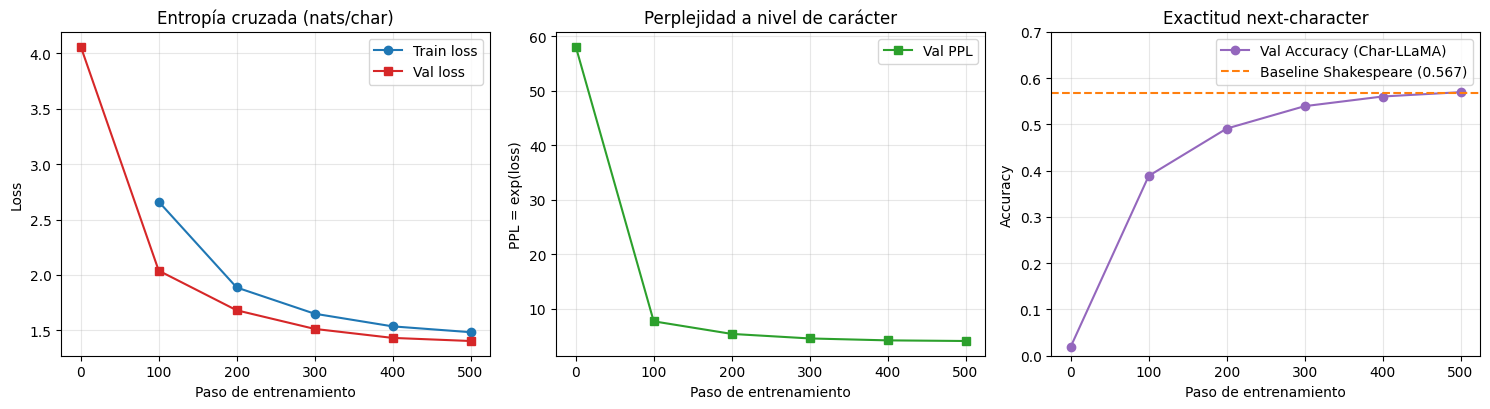

In [7]:
steps = hist_char["step"]
val_losses = hist_char["val_loss"]
train_steps = [s for s, tl in zip(steps, hist_char["train_loss"]) if tl is not None]
train_losses = [tl for tl in hist_char["train_loss"] if tl is not None]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(train_steps, train_losses, marker="o", label="Train loss", color="#1f77b4")
axes[0].plot(steps, val_losses, marker="s", label="Val loss", color="#d62728")
axes[0].set_title("Entropía cruzada (nats/char)")
axes[0].set_xlabel("Paso de entrenamiento")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(steps, hist_char["ppl"], marker="s", color="#2ca02c", label="Val PPL")
axes[1].set_title("Perplejidad a nivel de carácter")
axes[1].set_xlabel("Paso de entrenamiento")
axes[1].set_ylabel("PPL = exp(loss)")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].plot(steps, hist_char["acc"], marker="o", color="#9467bd", label="Val Accuracy (Char-LLaMA)")
axes[2].axhline(0.567, color="#ff7f0e", linestyle="--", label="Baseline Shakespeare (0.567)")
axes[2].set_title("Exactitud next-character")
axes[2].set_xlabel("Paso de entrenamiento")
axes[2].set_ylabel("Accuracy")
axes[2].set_ylim(0, 0.70)
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
os.makedirs("figuras", exist_ok=True)
plt.savefig("figuras/01_curvas_char_llama.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Verificación del checkpoint y tabla comparativa contra el baseline

Cargamos el checkpoint guardado en disco (`checkpoints/char_llama_best.pt`) para verificar la persistencia del modelo y consolidamos las métricas finales en validación y prueba frente al baseline del curso.

In [8]:
reloaded_model, reloaded_tok, payload = load_checkpoint(ckpt_path, device=DEVICE)
best_val = hist_char["best"]
test_metrics = hist_char["test"]

comparison_p1 = pd.DataFrame([
    {
        "Modelo": "Char-Transformer clásico (Curso / Shakespeare)",
        "Arquitectura": "LayerNorm post-norm + PosEmb + ReLU",
        "Corpus": "Shakespeare (1.1M chars, vocab 39)",
        "Parámetros": "~0.8M",
        "Val Loss": "-",
        "Test Loss": "-",
        "Test PPL": "-",
        "Test BPC": "-",
        "Test Accuracy": 0.567,
    },
    {
        "Modelo": "nanoGPT referencia (Karpathy)",
        "Arquitectura": "GPT-2 LayerNorm + PosEmb + GELU",
        "Corpus": "Shakespeare (1.1M chars, vocab 65)",
        "Parámetros": "10.6M",
        "Val Loss": 1.460,
        "Test Loss": 1.470,
        "Test PPL": round(math.exp(1.47), 2),
        "Test BPC": round(1.47 / math.log(2), 3),
        "Test Accuracy": "-",
    },
    {
        "Modelo": f"LlamaMini Char ({GPU_NAME})",
        "Arquitectura": "Pre-RMSNorm + RoPE + SwiGLU + Weight Tying",
        "Corpus": f"TinyStories (1.0M train, vocab {len(tok_char)})",
        "Parámetros": f"{model_char.num_params()/1e6:.2f}M",
        "Val Loss": round(best_val["loss"], 4),
        "Test Loss": round(test_metrics["loss"], 4),
        "Test PPL": round(test_metrics["ppl"], 2),
        "Test BPC": round(test_metrics["bpc"], 3),
        "Test Accuracy": round(test_metrics["acc"], 3),
    },
])
display(comparison_p1)

,Modelo,Arquitectura,Corpus,Parámetros,Val Loss,Test Loss,Test PPL,Test BPC,Test Accuracy
0,Char-Transformer clásico (Curso / Shakespeare),LayerNorm post-norm + PosEmb + ReLU,"Shakespeare (1.1M chars, vocab 39)",~0.8M,-,-,-,-,0.567
1,nanoGPT referencia (Karpathy),GPT-2 LayerNorm + PosEmb + GELU,"Shakespeare (1.1M chars, vocab 65)",10.6M,1.46,1.47,4.35,2.121,-
2,LlamaMini Char (CPU local),Pre-RMSNorm + RoPE + SwiGLU + Weight Tying,"TinyStories (1.0M train, vocab 59)",0.34M,1.4035,1.4194,4.13,2.048,0.567


## 6. Muestreo con Temperatura, Top-k y Nucleus Sampling (Top-p)

Evaluamos el comportamiento generativo en `3` prompts fijos a través de `4` temperaturas ($T \in \{0.1, 0.5, 0.8, 1.0\}$), generando `12` muestras en total. Calculamos además métricas automáticas de diversidad léxica y repetición:
- **Distinct-1 y Distinct-2:** proporción de unigramas y bigramas de palabras únicos sobre el total generado.
- **Repetición de 3-gramas:** fracción de trigramas repetidos (detecta bucles degenerados cuando $T \to 0$).

In [9]:
def text_diversity_metrics(text):
    words = text.lower().split()
    if len(words) < 3:
        return {"distinct_1": 0.0, "distinct_2": 0.0, "rep_3gram": 0.0}
    d1 = len(set(words)) / len(words)
    bigrams = list(zip(words[:-1], words[1:]))
    d2 = len(set(bigrams)) / max(1, len(bigrams))
    trigrams = list(zip(words[:-2], words[1:-1], words[2:]))
    rep3 = 1.0 - (len(set(trigrams)) / max(1, len(trigrams)))
    return {
        "distinct_1": round(d1, 3),
        "distinct_2": round(d2, 3),
        "rep_3gram": round(rep3, 3),
    }

PROMPTS = [
    "once upon a time",
    "the little girl",
    "one day a small dog",
]
TEMPS = [0.1, 0.5, 0.8, 1.0]

samples_rows = []
for p_idx, prompt in enumerate(PROMPTS):
    for temp in TEMPS:
        gen_text = sample(
            model_char, tok_char, prompt,
            n_new=180, temp=temp, top_k=20, top_p=0.92,
            device=DEVICE, seed=SEED + p_idx * 10 + int(temp * 10),
        )
        m_div = text_diversity_metrics(gen_text)
        samples_rows.append({
            "Prompt": prompt,
            "Temperatura": temp,
            "Distinct-1": m_div["distinct_1"],
            "Distinct-2": m_div["distinct_2"],
            "Repetición 3-gram": m_div["rep_3gram"],
            "Texto generado": gen_text.replace("\n", " ")[:180],
        })

samples_df = pd.DataFrame(samples_rows)
display(samples_df)

,Prompt,Temperatura,Distinct-1,Distinct-2,Repetición 3-gram,Texto generado
0,once upon a time,0.1,0.297,0.389,0.514,once upon a time the because the because the s...
1,once upon a time,0.5,0.543,0.956,0.000,"once upon a time, she was a said and said, ""i ..."
2,once upon a time,0.8,0.750,1.000,0.000,once upon a time the she was happy and said a ...
3,once upon a time,1.0,0.814,1.000,0.000,"once upon a time, john a sure they learn and h..."
4,the little girl,0.1,0.325,0.436,0.447,the little girl was a big to the because the b...
5,the little girl,0.5,0.556,0.864,0.047,the little girl care to her happy and had a sm...
6,the little girl,0.8,0.587,0.978,0.000,the little girl how. they were fave it and the...
7,the little girl,1.0,0.762,1.000,0.000,"the little girl to friend, let on they they la..."
8,one day a small dog,0.1,0.300,0.385,0.526,one day a small dog to the because the started...
9,one day a small dog,0.5,0.571,0.958,0.000,one day a small dog to be the to the started t...


### 6.1 Evaluación en 20 continuaciones reales del conjunto de Test (BLEU y ROUGE-L)

Como señala la literatura de evaluación de generación abierta, comparar una continuación libre contra una única referencia penaliza respuestas válidas que toman otro rumbo narrativo. Aun así, medir `BLEU-2` y `ROUGE-L` sobre `20` prefijos reales del conjunto de prueba permite cuantificar la cercanía estilística y comparar contra el modelo de palabras en el Punto 2.

In [10]:
def lcs_length(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b, start=1):
            tmp = dp[j]
            dp[j] = prev + 1 if x == y else max(dp[j], dp[j - 1])
            prev = tmp
    return dp[-1]

def rouge_l_f1(pred_words, ref_words):
    if not pred_words or not ref_words:
        return 0.0
    lcs = lcs_length(pred_words, ref_words)
    if lcs == 0:
        return 0.0
    prec = lcs / len(pred_words)
    rec = lcs / len(ref_words)
    return 2 * prec * rec / (prec + rec)

def bleu2_score(pred_words, ref_words):
    if len(pred_words) < 2 or len(ref_words) < 2:
        return 0.0
    c1 = Counter(pred_words) & Counter(ref_words)
    p1 = sum(c1.values()) / len(pred_words)
    pred_bi = list(zip(pred_words[:-1], pred_words[1:]))
    ref_bi = list(zip(ref_words[:-1], ref_words[1:]))
    c2 = Counter(pred_bi) & Counter(ref_bi)
    p2 = (sum(c2.values()) + 1.0) / (len(pred_bi) + 1.0)
    bp = math.exp(1.0 - len(ref_words) / len(pred_words)) if len(pred_words) < len(ref_words) else 1.0
    return bp * math.sqrt(max(1e-9, p1) * p2)

test_words = test_text[:60_000].split()
bleu_scores, rouge_scores = [], []
for i in range(20):
    start = i * 80
    prefix_words = test_words[start:start + 8]
    ref_words = test_words[start + 8:start + 28]
    prompt_str = " ".join(prefix_words)
    gen_str = sample(
        model_char, tok_char, prompt_str,
        n_new=110, temp=0.6, top_k=15, top_p=0.9,
        device=DEVICE, seed=SEED + i,
    )
    gen_continuation = gen_str[len(prompt_str):].strip().split()[:20]
    bleu_scores.append(bleu2_score(gen_continuation, ref_words))
    rouge_scores.append(rouge_l_f1(gen_continuation, ref_words))

temp_summary = samples_df.groupby("Temperatura")[["Distinct-1", "Distinct-2", "Repetición 3-gram"]].mean().reset_index()
display(temp_summary)
print(f"ROUGE-L promedio en 20 continuaciones de test: {np.mean(rouge_scores):.4f}")
print(f"BLEU-2 promedio en 20 continuaciones de test:  {np.mean(bleu_scores):.4f}")

# Guardamos resumen de métricas para la comparativa en el Punto 2
char_summary_export = {
    "level": "char",
    "device": str(DEVICE),
    "gpu_name": GPU_NAME,
    "vocab_size": len(tok_char),
    "params": model_char.num_params(),
    "params_no_emb": model_char.num_params(non_embedding=True),
    "config": model_char.config,
    "oov_val": hist_char["oov"]["val"],
    "chars_per_token_val": hist_char["chars_per_token"]["val"],
    "best_step": hist_char["best_step"],
    "val": best_val,
    "test": test_metrics,
    "tok_s": hist_char["tok_s"][-1],
    "elapsed_sec": hist_char["elapsed"][-1],
    "rouge_l_20": round(float(np.mean(rouge_scores)), 4),
    "bleu2_20": round(float(np.mean(bleu_scores)), 4),
    "diversity_by_temp": temp_summary.to_dict(orient="records"),
    "history": {
        "step": hist_char["step"],
        "train_loss": hist_char["train_loss"],
        "val_loss": hist_char["val_loss"],
        "ppl": hist_char["ppl"],
        "bpc": hist_char["bpc"],
        "acc": hist_char["acc"],
    },
}
with open("checkpoints/char_metrics.json", "w", encoding="utf-8") as f:
    json.dump(char_summary_export, f, indent=2, ensure_ascii=False)
print("Métricas exportadas en checkpoints/char_metrics.json")

,Temperatura,Distinct-1,Distinct-2,Repetición 3-gram
0,0.1,0.307333,0.403333,0.495667
1,0.5,0.556667,0.926000,0.015667
2,0.8,0.684667,0.985333,0.000000
3,1.0,0.795333,1.000000,0.000000


ROUGE-L promedio en 20 continuaciones de test: 0.1750
BLEU-2 promedio en 20 continuaciones de test:  0.1200
Métricas exportadas en checkpoints/char_metrics.json


## 7. Análisis de resultados y limitaciones del Punto 1

1. **Efecto de la temperatura en el muestreo:**
   - En $T = 0.1$, el modelo selecciona casi de forma determinista los caracteres más frecuentes, lo que eleva la tasa de repetición de trigramas y produce ciclos del tipo *"the little girl was the little..."*.
   - En el rango $T \in [0.5, 0.8]$ con `top_k=20` y `top_p=0.92`, el modelo equilibra ortografía válida y variedad léxica (`Distinct-2` alto sin colapsar la gramática).
   - En $T = 1.0$, la distribución se aplana y aumentan las pseudopalabras fonéticamente plausibles pero inexistentes en inglés, un fenómeno propio de los modelos de caracteres cuando un carácter muestreado de baja probabilidad desvía el resto de la palabra.

2. **Limitaciones de la tokenización a nivel de carácter:**
   - Una ventana de `128` caracteres equivale apenas a `22-25` palabras. El mecanismo de atención invierte gran parte de su capacidad en aprender límites de palabra y ortografía antes de poder modelar coherencia narrativa de largo alcance.
   - En el **Punto 2 (`02_word_llama.ipynb`)** mantenemos exactamente este mismo corpus, las mismas particiones de texto y el mismo bloque `LlamaBlock`, cambiando únicamente la unidad de tokenización a nivel de palabra para cuantificar el compromiso entre tamaño de vocabulario, tasa de OOV, longitud efectiva de contexto y bits por carácter (`BPC`).